# 2. Le chaos dans le problème à trois corps

Un système est **chaotique** quand deux états initiaux presque identiques s'écartent exponentiellement vite :

$$d(t) \approx d_0 \, e^{\lambda t}$$

$\lambda$ est le plus grand **exposant de Lyapunov**. Le mouvement reste déterministe, mais toute erreur
(de mesure ou d'arrondi) est amplifiée, donc la prévision à long terme est impossible.

On compare deux situations avec trois masses égales :

- `chaotic` : un départ 3D quelconque, où les trois corps interagissent fortement ;
- `figure_eight` : l'orbite en huit, périodique et stable.

In [1]:
import numpy as np

from threebody import chaotic, figure_eight
from threebody.chaos import divergence, escape_time_map, lyapunov_estimate
from threebody.plots import plot_divergence, plot_escape_map, plot_lyapunov

scenarios = {"chaotic": chaotic(), "figure_eight": figure_eight()}
T_END = 60.0

## Expérience 1 : deux simulations jumelles

On lance deux simulations qui ne diffèrent que de $10^{-8}$ sur la position d'un corps, et on suit leur distance
dans l'espace des phases (positions et vitesses).

chaotic       distance: 1.0e-08 -> 2.7e+01
figure_eight  distance: 1.0e-08 -> 2.8e-06


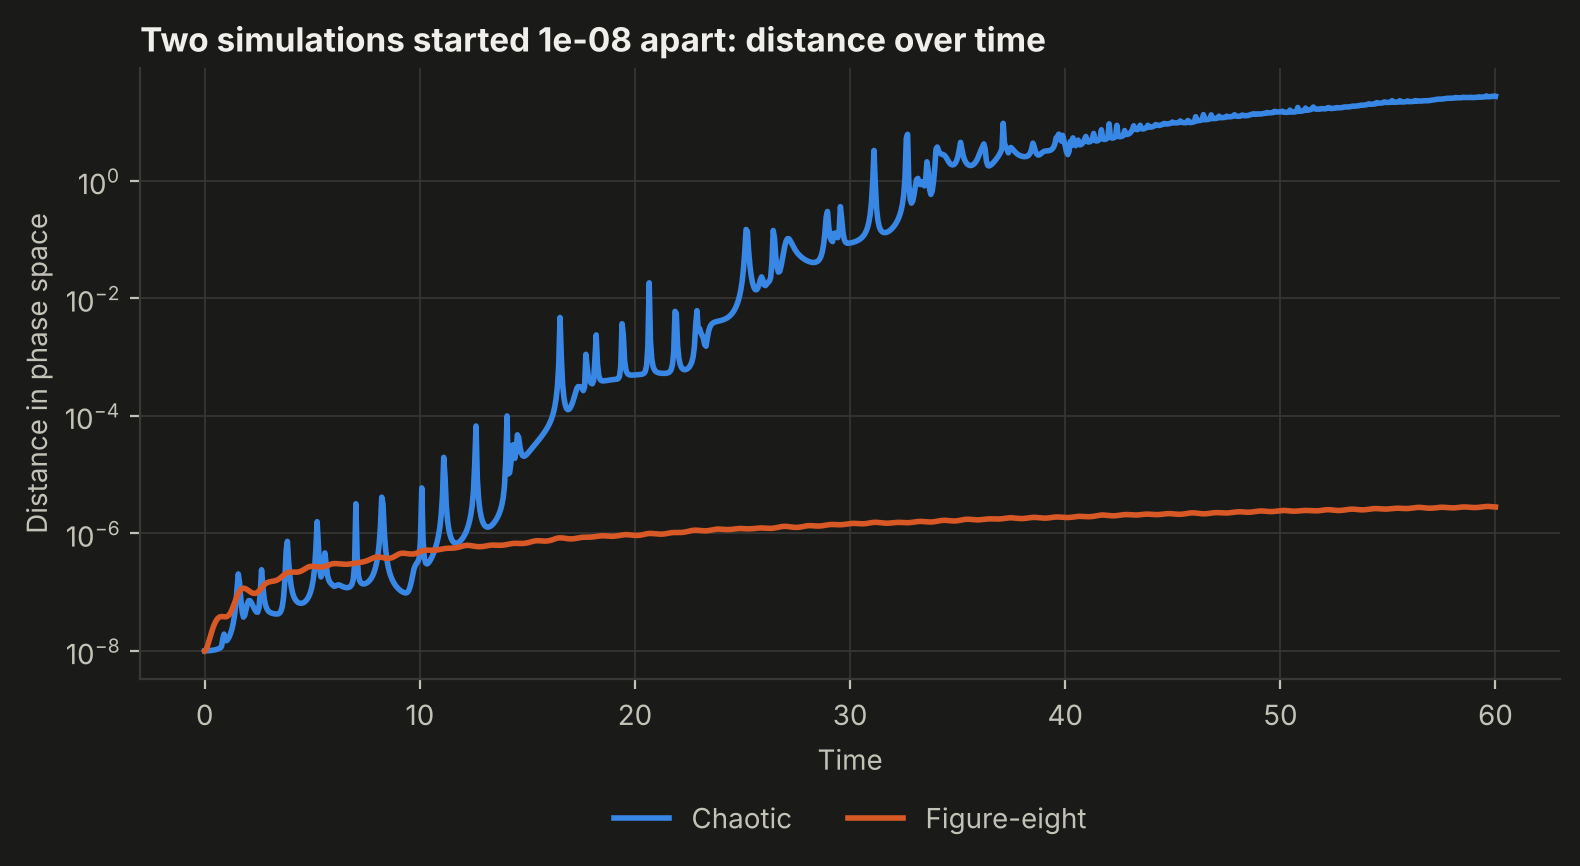

In [2]:
curves = {name: divergence(ic, delta=1e-8, t_end=T_END) for name, ic in scenarios.items()}

for name, (t, d) in curves.items():
    print(f"{name:13s} distance: {d[0]:.1e} -> {d[-1]:.1e}")

fig = plot_divergence(curves, title="Two simulations started 1e-08 apart: distance over time")

**Lecture du graphique** (axe vertical logarithmique)

- Départ chaotique : la distance suit en moyenne une droite, donc une croissance **exponentielle**.
  L'écart est multiplié par cent millions, puis sature : les deux simulations n'ont alors plus rien à voir.
  Les pics correspondent aux rencontres proches entre deux corps.
- Orbite en huit : la distance grandit lentement (croissance polynomiale), les deux simulations restent voisines.

## Expérience 2 : l'exposant de Lyapunov

La méthode de Benettin suit deux trajectoires voisines pendant un court intervalle, enregistre la croissance de leur
écart, puis ramène la voisine à sa distance initiale, et recommence. La moyenne des taux de croissance donne $\lambda$.

chaotic       lambda ~ 0.454
figure_eight  lambda ~ 0.094


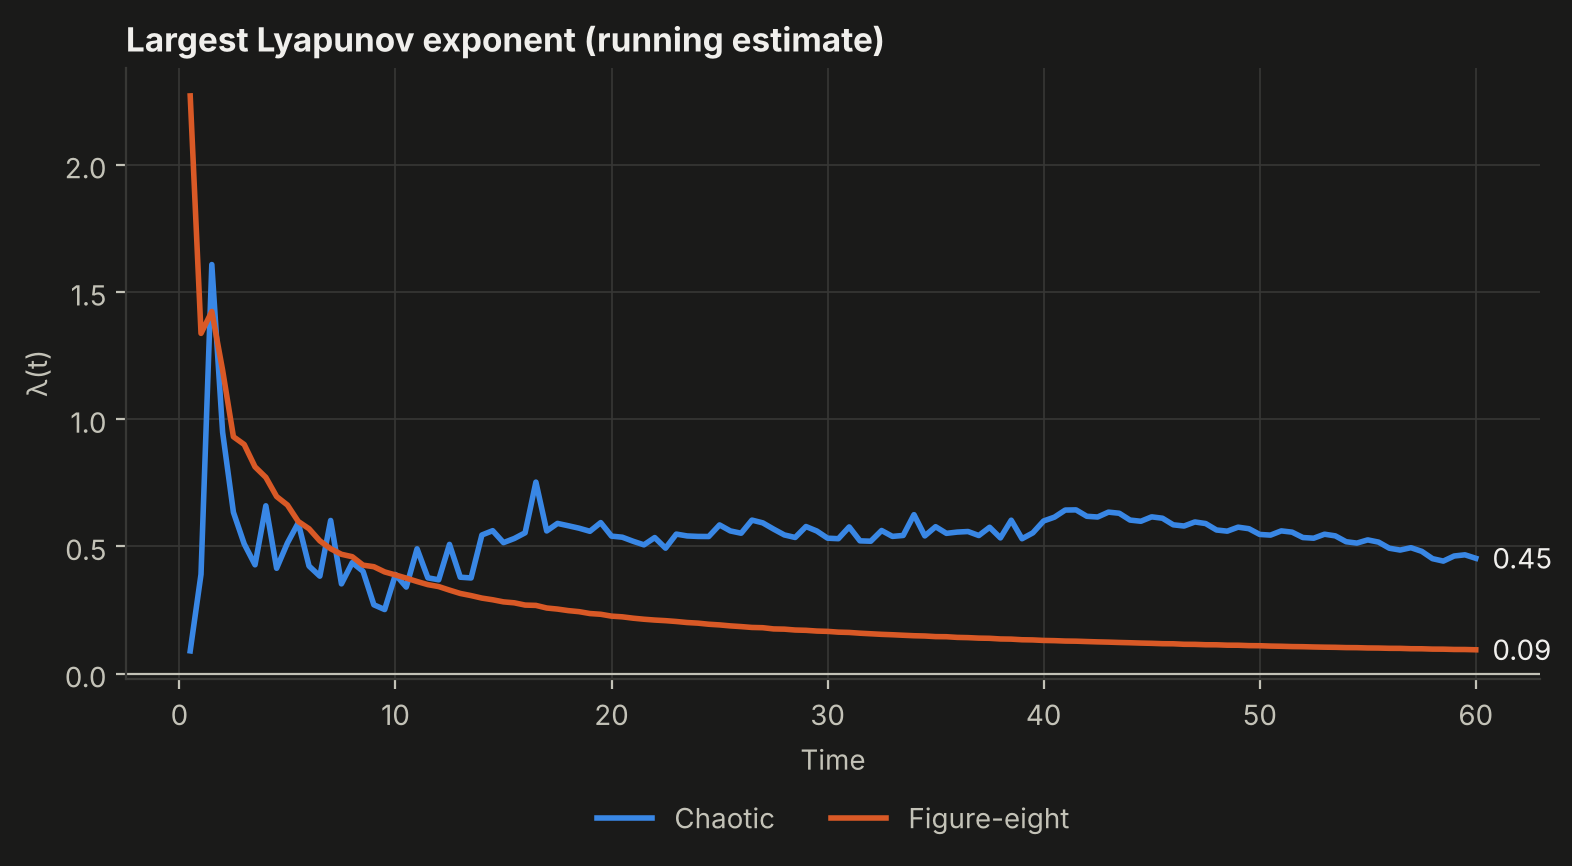

In [3]:
lyap = {name: lyapunov_estimate(ic, t_end=T_END) for name, ic in scenarios.items()}

for name, (t, lam) in lyap.items():
    print(f"{name:13s} lambda ~ {lam[-1]:.3f}")

fig = plot_lyapunov(lyap)

Pour le départ chaotique, l'estimation se stabilise autour d'une valeur positive : l'écart est multiplié par $e$
environ toutes les $1/\lambda$ unités de temps. Pour l'orbite en huit, l'estimation décroît vers zéro
(comme $\ln t / t$), ce qui est le comportement d'une orbite régulière.

C'est une estimation **à temps fini** : si un corps est éjecté, il ne reste qu'une binaire et un corps isolé,
le mouvement redevient régulier et $\lambda(t)$ se met à décroître.

## Expérience 3 : une carte du chaos

Problème de la chute libre (Agekyan & Anosova) : trois masses égales lâchées **sans vitesse**.
Les corps 1 et 2 partent de $(-0.5, 0)$ et $(0.5, 0)$. Chaque pixel est une position de départ du corps 3,
et sa couleur est le temps écoulé avant qu'un corps soit éjecté.

La grille est petite ici pour que le calcul reste rapide. Pour une image fine :
`python scripts/chaos_map.py --n 400`.

ejection before t = 40 for 69% of the starting points


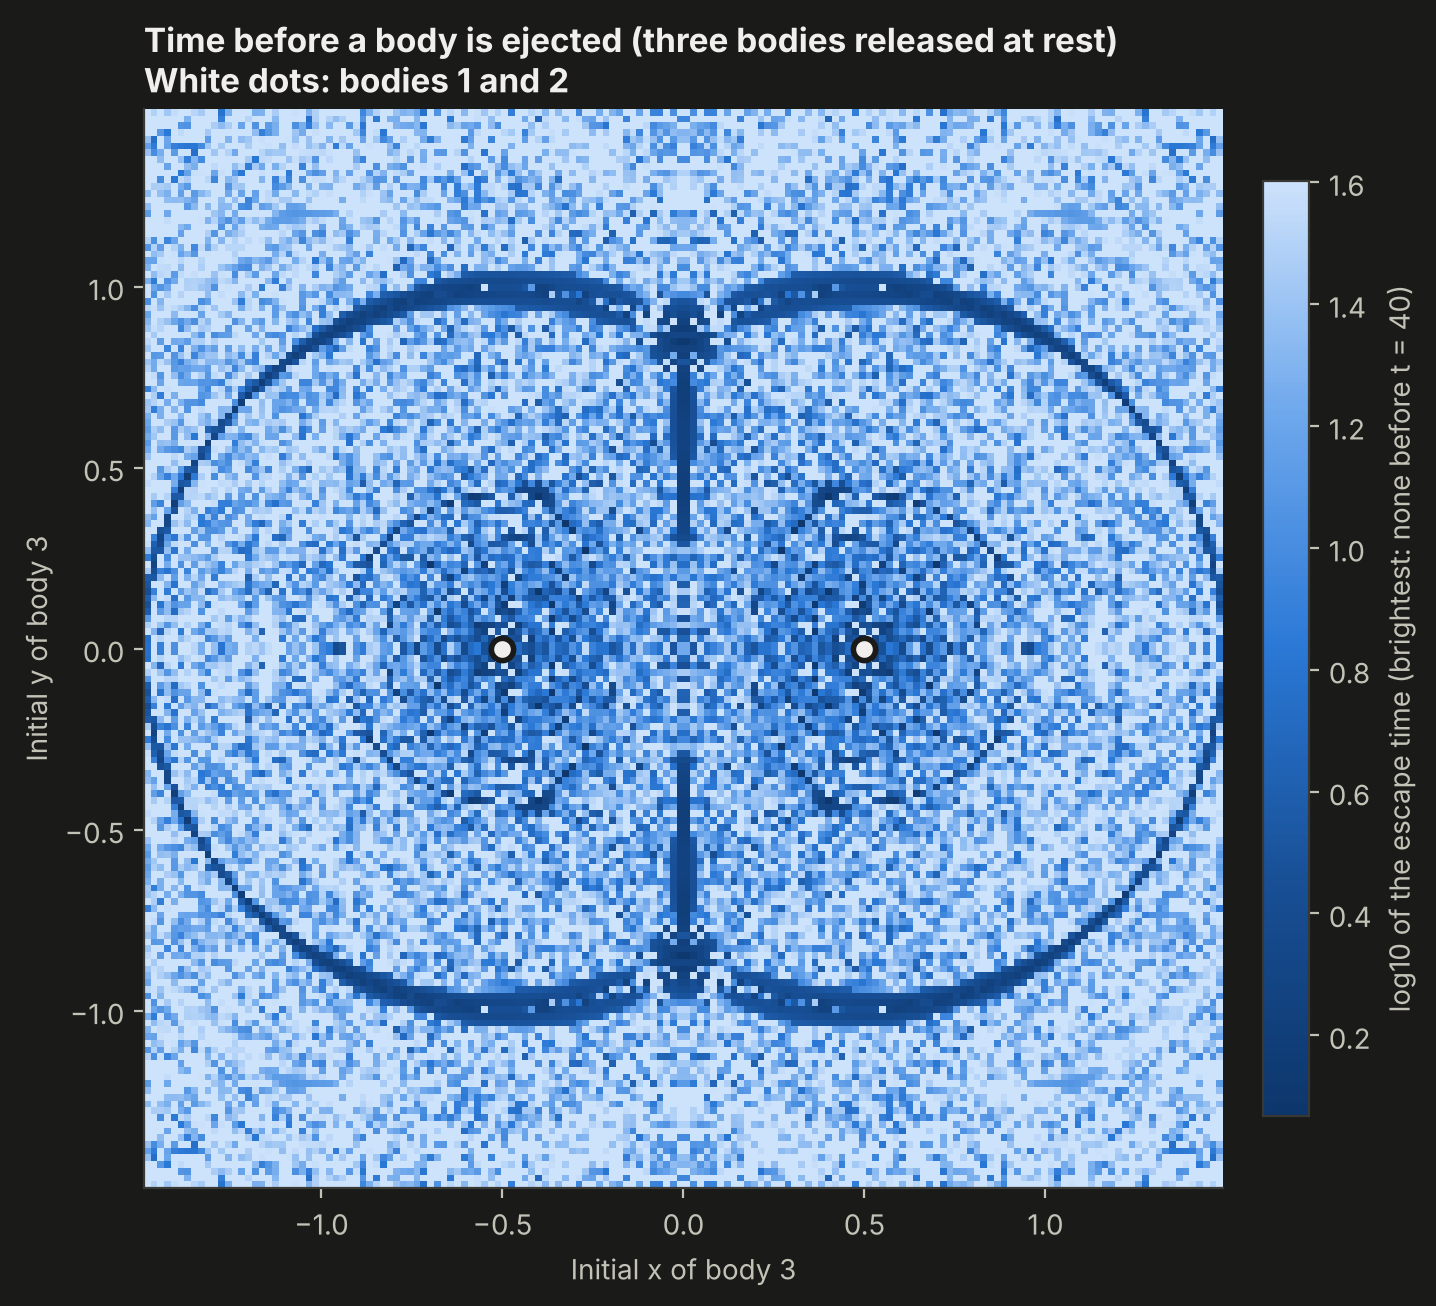

In [4]:
n, size, t_max = 80, 1.5, 40.0
xs = (np.arange(n) + 0.5) * size / n  # one quadrant; the rest follows by symmetry

t_escape = escape_time_map(xs, xs, t_max=t_max)
print(f"ejection before t = {t_max:g} for {np.mean(~np.isnan(t_escape)):.0%} of the starting points")

fig = plot_escape_map(xs, xs, t_escape, t_max)

Les zones unies sont régulières : des départs voisins donnent le même destin. Les zones mouchetées sont chaotiques :
deux pixels voisins donnent des durées de vie complètement différentes, et la frontière entre les zones a une structure
fractale. C'est l'image de la sensibilité aux conditions initiales.

## À retenir

- Le problème à trois corps est chaotique en général, mais il contient des îlots réguliers (orbite en huit, etc.).
- Le chaos se mesure : divergence exponentielle de deux trajectoires, exposant de Lyapunov positif.
- Une simulation chaotique reste utile : la trajectoire précise n'est pas prévisible à long terme,
  mais les grandeurs conservées et les propriétés statistiques restent fiables.